# 🎯 Superstore Demand Forecasting — Holdout Validation
**Tools:** Python · Pandas · statsmodels · Matplotlib  
**Goal:** Measure real forecast error on the 12 holdout months (Jan–Dec 2017) for the two baselines and Holt-Winters, using MAPE and WAPE.

---

| Section | Question it answers |
|---|---|
| 1. Setup | Which data is the model allowed to see? |
| 2. Metrics | How are MAPE and WAPE calculated? |
| 3. Baselines | How good are the simplest possible forecasts? |
| 4. Holt-Winters | Which Holt-Winters variant does the training data choose? |
| 5. Holdout results | Does Holt-Winters beat the baselines? |
| 6. Findings | What does this mean for the next models? |

---
## 1. SETUP
> **Goal:** Load the four monthly series and split off the 12 holdout months. Every model below is fitted on the 36 training months only, and every choice between models is made without looking at the holdout.

In [1]:
import itertools
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from src.baselines import naive_forecast, seasonal_naive_forecast
from src.config import HOLDOUT_MONTHS, OUTPUTS_DIR
from src.metrics import mape, wape
from src.plotting import AXIS, INK, MUTED, SERIES_COLORS, apply_style, thousands
from src.series import SERIES, load_monthly_sales, split_holdout

apply_style()

PHASE_DIR = OUTPUTS_DIR / "phase4_validation"
(PHASE_DIR / "figures").mkdir(parents=True, exist_ok=True)
(PHASE_DIR / "tables").mkdir(parents=True, exist_ok=True)

sales = load_monthly_sales()
train, holdout = split_holdout(sales)
print(f"Train   : {len(train)} months  ({train.index.min():%b %Y} → {train.index.max():%b %Y})")
print(f"Holdout : {len(holdout)} months  ({holdout.index.min():%b %Y} → {holdout.index.max():%b %Y})")

Train   : 36 months  (Jan 2014 → Dec 2016)
Holdout : 12 months  (Jan 2017 → Dec 2017)


---
## 2. METRICS
> **Goal:** Define the two error measures used throughout. Both are in `src/metrics.py` and covered by tests.

| Metric | Formula | Reads as |
|---|---|---|
| **MAPE** | average over months of \|actual − forecast\| ÷ actual | "on a typical month, the forecast is off by X%" |
| **WAPE** | sum of \|actual − forecast\| ÷ sum of actual | "of all the units sold in the period, X% were mis-forecast" |

**WAPE is the headline metric.** MAPE gives every month equal weight, so a 50% miss on a quiet February counts as much as a 50% miss on December, which sells several times more. WAPE weights each month by its sales, which is what matters for inventory: the money is in the big months.

---
## 3. BASELINES
> **Goal:** Score the two simplest forecasts. Any model worth using has to beat these.

- **Naive:** every 2017 month = December 2016.
- **Seasonal naive:** each 2017 month = the same month of 2016 (Jan 2017 = Jan 2016, and so on).

In [2]:
forecasts = {
    "Naive": {name: naive_forecast(train[name], HOLDOUT_MONTHS) for name in SERIES},
    "Seasonal naive": {name: seasonal_naive_forecast(train[name], HOLDOUT_MONTHS) for name in SERIES},
}

def score(model):
    return pd.DataFrame({
        name: {"MAPE": mape(holdout[name], fc), "WAPE": wape(holdout[name], fc)}
        for name, fc in forecasts[model].items()
    }).T

pd.concat({model: score(model) for model in forecasts}, axis=1).round(1)

Naive        Seasonal naive      
                  MAPE   WAPE           MAPE  WAPE
Total             97.3   64.6           24.5  25.3
Furniture        180.0  104.7           24.0  20.9
Office Supplies  127.8   85.3           32.1  35.9
Technology        54.1   38.9           41.4  34.6

The naive forecast is badly off because December 2016 was a peak month: repeating it for all of 2017 overshoots every month except the year-end peak. The seasonal naive forecast is far better, which matches the exploration's finding that seasonality is the main signal and month-to-month memory is weak.

---
## 4. HOLT-WINTERS
> **Goal:** Fit Holt-Winters (exponential smoothing with level, trend and seasonality) and let the **training data** choose the variant for each series.

The exploration left two questions open (findings 4 and 6), so six variants are fitted:

| Choice | Options |
|---|---|
| Trend | none · additive · additive damped (growth that flattens out) |
| Seasonality | additive (fixed \$ swing) · multiplicative (fixed % swing) |

The variant is chosen by **AICc** on the training months: a score that rewards fitting the data well and penalises extra parameters, corrected for small samples. Lower is better. The holdout plays no part in the choice.

In [3]:
VARIANTS = {
    (trend_label, seasonal): dict(trend=trend, damped_trend=damped, seasonal=seasonal)
    for (trend_label, trend, damped), seasonal in itertools.product(
        [("none", None, False), ("additive", "add", False), ("additive damped", "add", True)],
        ["add", "mul"],
    )
}

def fit_holt_winters(series, variant):
    with warnings.catch_warnings():
        # A few fits warn that the optimiser did not fully converge; their AICc still ranks them.
        warnings.simplefilter("ignore")
        return ExponentialSmoothing(
            series, seasonal_periods=12, initialization_method="estimated", **VARIANTS[variant]
        ).fit()

fits = {(name, variant): fit_holt_winters(train[name], variant) for name in SERIES for variant in VARIANTS}

aicc = pd.DataFrame(
    {variant: {name: fits[(name, variant)].aicc for name in SERIES} for variant in VARIANTS}
)
aicc.columns = pd.MultiIndex.from_tuples(aicc.columns, names=["trend", "seasonal"])
aicc.round(1)

trend             none        additive        additive damped       
seasonal           add    mul      add    mul             add    mul
Total            697.8  695.7    717.5  711.0           721.5  720.5
Furniture        623.1  616.0    634.1  628.3           650.4  639.4
Office Supplies  653.4  647.8    679.1  662.3           689.0  671.6
Technology       679.4  677.9    699.5  696.9           708.8  702.6

In [4]:
chosen = aicc.idxmin(axis=1)
print("Variant chosen by AICc on the training months:")
for name, (trend, seasonal) in chosen.items():
    print(f"  {name:<16} trend = {trend:<16} seasonal = {'multiplicative' if seasonal == 'mul' else 'additive'}")

forecasts["Holt-Winters"] = {name: fits[(name, chosen[name])].forecast(HOLDOUT_MONTHS) for name in SERIES}

Variant chosen by AICc on the training months:
  Total            trend = none             seasonal = multiplicative
  Furniture        trend = none             seasonal = multiplicative
  Office Supplies  trend = none             seasonal = multiplicative
  Technology       trend = none             seasonal = multiplicative


---
## 5. HOLDOUT RESULTS
> **Goal:** Compare all three forecasts on the 12 months none of them saw.

### 5.1 — MAPE and WAPE on the Holdout

In [5]:
scores = pd.concat({model: score(model) for model in forecasts}, axis=1)
scores.index.name = "series"
scores.to_csv(PHASE_DIR / "tables" / "holdout_scores.csv")

wape_table = scores.xs("WAPE", axis=1, level=1).copy()
wape_table["Holt-Winters beats seasonal naive?"] = wape_table["Holt-Winters"] < wape_table["Seasonal naive"]
wape_table["WAPE change vs seasonal naive (pts)"] = wape_table["Holt-Winters"] - wape_table["Seasonal naive"]

print("--- MAPE and WAPE, % ---")
print(scores.round(1).to_string())
print()
wape_table.round(1)

--- MAPE and WAPE, % ---
                 Naive        Seasonal naive       Holt-Winters      
                  MAPE   WAPE           MAPE  WAPE         MAPE  WAPE
series                                                               
Total             97.3   64.6           24.5  25.3         23.3  22.5
Furniture        180.0  104.7           24.0  20.9         32.4  23.8
Office Supplies  127.8   85.3           32.1  35.9         28.6  29.2
Technology        54.1   38.9           41.4  34.6         31.9  33.5



,Naive,Seasonal naive,Holt-Winters,Holt-Winters beats seasonal naive?,WAPE change vs seasonal naive (pts)
series,,,,,
Total,64.6,25.3,22.5,True,-2.8
Furniture,104.7,20.9,23.8,False,2.9
Office Supplies,85.3,35.9,29.2,True,-6.6
Technology,38.9,34.6,33.5,True,-1.1


### 5.2 — Forecasts against Actual Sales

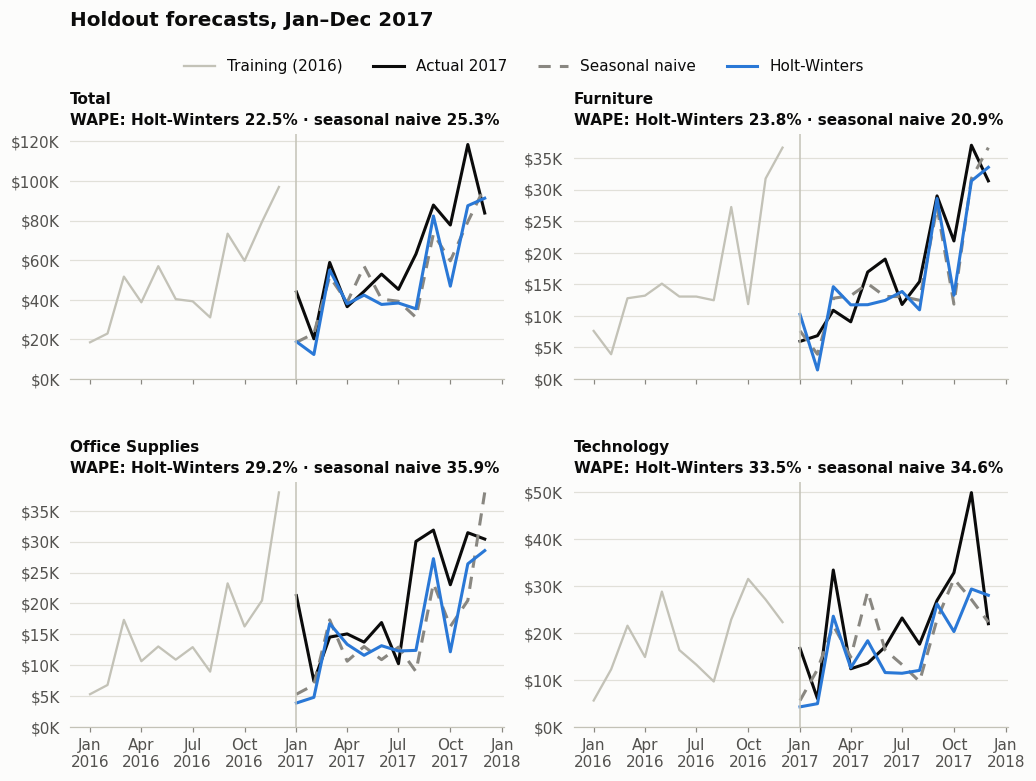

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, gridspec_kw={"hspace": 0.42, "wspace": 0.16})
context = train.loc["2016"]

for ax, name in zip(axes.flat, SERIES):
    ax.plot(context.index, context[name], color=AXIS, linewidth=1.5, label="Training (2016)")
    ax.plot(holdout.index, holdout[name], color=INK, label="Actual 2017")
    ax.plot(holdout.index, forecasts["Seasonal naive"][name], color=MUTED, linestyle=(0, (4, 3)), label="Seasonal naive")
    ax.plot(holdout.index, forecasts["Holt-Winters"][name], color=SERIES_COLORS["Furniture"], label="Holt-Winters")
    hw, sn = scores.loc[name, ("Holt-Winters", "WAPE")], scores.loc[name, ("Seasonal naive", "WAPE")]
    ax.set_title(f"{name}\nWAPE: Holt-Winters {hw:.1f}% · seasonal naive {sn:.1f}%", fontsize=10, linespacing=1.5)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(thousands)
    ax.axvline(holdout.index[0], color=AXIS, linewidth=1)

for ax in axes[-1]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=4)
fig.suptitle("Holdout forecasts, Jan–Dec 2017", x=0.125, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.savefig(PHASE_DIR / "figures" / "01_holdout_forecasts.png")
plt.show()

### 5.3 — Bias: Too High or Too Low?
WAPE says how big the errors are, not which way they go. Bias is the total forecast minus total actual sales over the 12 months, as a % of actual sales. Negative means the forecast was too low, which in inventory terms means stock-outs.

In [7]:
actual_growth = holdout.sum() / train.loc["2016"].sum() - 1
bias = pd.DataFrame({
    model: {name: (forecasts[model][name].sum() / holdout[name].sum() - 1) * 100 for name in SERIES}
    for model in ["Seasonal naive", "Holt-Winters"]
})
bias.insert(0, "Actual growth 2016 → 2017 (%)", actual_growth * 100)
bias.round(1)

,Actual growth 2016 → 2017 (%),Seasonal naive,Holt-Winters
Total,20.4,-16.9,-20.0
Furniture,8.3,-7.7,-9.9
Office Supplies,33.8,-25.3,-25.8
Technology,20.0,-16.7,-25.4


### 5.4 — Diagnostic Only: Holdout WAPE of Every Variant
For understanding, not for choosing. Picking the variant with the lowest number in this table would use the holdout to make a decision, and its WAPE would then no longer be an honest estimate of future error.

In [8]:
variant_wape = pd.DataFrame({
    variant: {name: wape(holdout[name], fits[(name, variant)].forecast(HOLDOUT_MONTHS)) for name in SERIES}
    for variant in VARIANTS
})
variant_wape.columns = pd.MultiIndex.from_tuples(variant_wape.columns, names=["trend", "seasonal"])
variant_wape.round(1)

trend            none       additive       additive damped      
seasonal          add   mul      add   mul             add   mul
Total            18.6  22.5     18.7  20.3            17.7  22.0
Furniture        22.0  23.8     20.6  23.5            22.3  23.8
Office Supplies  39.0  29.2     33.5  25.5            36.7  25.6
Technology       33.3  33.5     38.0  35.9            38.1  33.5

---
## 6. FINDINGS

| # | Finding | Evidence (holdout, Jan–Dec 2017) |
|---|---|---|
| 1 | **The naive forecast is unusable.** | WAPE 39–105%. Repeating December's peak for a whole year overshoots almost every month. |
| 2 | **Seasonal naive is a strong benchmark.** | WAPE 20.9–35.9% with no model at all, just last year's months. |
| 3 | **Holt-Winters beats seasonal naive on 3 of 4 series.** | WAPE: Total 22.5% vs 25.3%, Office Supplies 29.2% vs 35.9%, Technology 33.5% vs 34.6% (a marginal gain). It loses on Furniture: 23.8% vs 20.9%. |
| 4 | **Every forecast is too low.** | 2017 sales grew 20.4% over 2016. Holt-Winters under-forecast the year by 20.0% in total (Office Supplies by 25.8%, Technology by 25.4%). For inventory, this means stock-outs. |
| 5 | **The cause is the trend choice.** | AICc chose *no trend* and *multiplicative seasonality* for all four series: the flat 2015 in the training data made growth look like noise. |
| 6 | **The holdout cannot be used to fix this.** | Section 5.4 shows that the best variant differs by series and that no variant removes the under-forecast. Choosing a variant from that table would make its WAPE an optimistic, not an honest, number. |

### What this means for the next steps
- **SARIMA** is next, scored on the same holdout against the same benchmark: seasonal naive.
- **Growth is the open problem.** The final forecast will be refitted on all 48 months, which include 2017's growth, so the trend may be chosen differently there. That choice still has to be made on the training data, not tuned to the holdout.
- **Inventory planning must allow for under-forecasting.** Until a model removes the bias, the upper confidence bound is a safer planning number than the point forecast, especially for Office Supplies and Technology.